# Frequency response at the center of a square transmitter loop.
## *comparing approaches.*
Matt Griffiths

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [8]:
import torch
from em1d.experiment import Loop, Receiver
from em1d.transforms import Hankel
from em1d.physics import refl_transverse_electric as rte, freespace_u0 as u0

In [9]:
# first lets compute Hz(R)

In [10]:
lp = Loop.square(50)
lp.x += 0.005156154881
rx = Receiver()

In [11]:
rmin = lp.min_horizontal_distance(rx)
rmax = lp.max_horizontal_distance(rx)

In [13]:
def integrand(wave_length):
    sigma = torch.tensor([10, 1., 10])[:,None,None]
    thick = torch.tensor([25, 50])[:,None,None]
    omega = torch.tensor([100.])[None,:,None]*2*torch.pi
    lmb = wave_length[None, None, :]
    intg = (1.+rte(sigma, thick, omega, lmb))*lmb**2 / u0(omega, lmb)
    print(intg.shape)
    return intg


hkl = Hankel(integrand, 1)

torch.Size([1, 1, 301])


In [24]:
r, hr = hkl.range(rmin, rmax)

In [27]:
r.numpy().shape
# hr.numpy().shape

(5,)

In [33]:
from scipy.interpolate import interp1d

int_hr = interp1d(np.log10(r.numpy()), np.squeeze(hr.numpy()))

def hr_interp(r):
    return int_hr(np.log10(r))

In [34]:
from em1d.transforms import plot_loglog
from em1d.experiment import getRz

RuntimeError: "lt_cpu" not implemented for 'ComplexFloat'

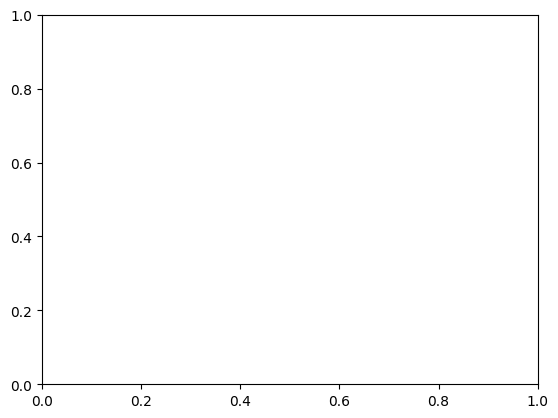

In [35]:
fig,axs = plt.subplots()
axs = plot_loglog(r, hr, ax=axs)
axs.set_xscale('linear')

In [36]:
from numpy.linalg import norm


def integrate_around_loop(lp, rx, hr):
    lp_xyz = lp.xyz - rx.xyz[None, ...]

    HR = 0+0j
    n_dipoles = 0
    for i in range(len(lp)-1):
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = np.einsum('...i,...i->...', Rz, lp_xyz[i])
        p2 = np.einsum('...i,...i->...', Rz, lp_xyz[i+1])

        p12 = p2-p1
        tdist = norm(p12, axis=-1)
        p12 /= tdist
        cp = p1
        cdist = 0

        while cdist < tdist:
            cR = norm(cp)
            ds = cR/15.
            if cdist+ds > tdist:
                ds = tdist-cdist
                cdist += cR/15
            else:
                cdist += ds
            HR += ds*p1[1]*hr(cR)/cR
            cp += ds*p12
            n_dipoles +=1
    return HR

In [37]:
hz_loop = integrate_around_loop(lp, Receiver(), hr_interp)

In [38]:
print(r)
lp = Loop.square(50)
s = lp.s_of_r(Receiver(), r)
print(s)

tensor([15.8489+0.j, 19.9526+0.j, 25.1189+0.j, 31.6228+0.j, 39.8107+0.j])


TypeError: Concatenation operation is not implemented for NumPy arrays, use np.concatenate() instead. Please do not rely on this error; it may not be given on all Python implementations.

In [14]:
hz_sr = (hr/r).dot(s+0j)

<Axes: >

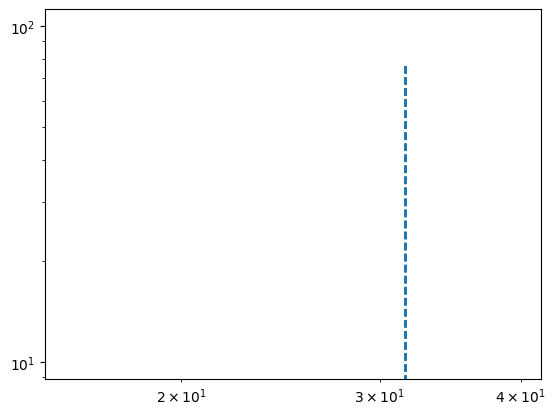

In [15]:
fig,axs=plt.subplots()
# plot_loglog(r, hr*(s+0j) / r, ax=axs)
plot_loglog(r, s, ax=axs)

In [16]:
print(hz_loop)
print(hz_sr)

(-0.1340046122446195+0.09718647877708174j)
(-0.001159191413843492+0.0011046290629078558j)


In [17]:
lp = Loop.square(50)

xy = np.linspace(-100, 100, 51)
HZ2 = np.zeros((len(xy), len(xy)), dtype=complex)

rxall = Receiver(x=xy, y=xy)
rmin = lp.min_horizontal_distance(rxall)
rmax = lp.max_horizontal_distance(rxall)
print(rmin, rmax)
hkl = Hankel(integrand, 1, smp_per_decade=20)
r, hr = hkl.range(rmin, rmax)
int_hr = interp1d(r, hr, kind='nearest')

def hr_interp(r):
    return int_hr(r)


for i in range(len(xy)):
    for j in range(len(xy)):
        rx = Receiver(x=xy[i], y=xy[j])
        hz_loop = integrate_around_loop(lp, rx, hr_interp)
        HZ2[i,j] = hz_loop
    print(f'{i}of{len(xy)}', flush=True, end='\r')

1.0 176.7766952966369
(1, 1, 1, 1, 1, 1, 1, 601)


In [18]:
HZ = np.zeros((len(xy), len(xy)), dtype=complex)

rxall = Receiver(x=xy, y=xy)
rmin = lp.min_horizontal_distance(rxall)
rmax = lp.max_horizontal_distance(rxall)
r, hr = hkl.range(rmin, rmax)

dr = np.gradient(r)

for i in range(len(xy)):
    for j in range(len(xy)):
        rx = Receiver(x=xy[i], y=xy[j])
        s = lp.s_of_r(rx, r)
        s = np.convolve(s, np.array([2, 8, 1])/11, mode='same')+0j
        # hrs = np.convolve(hr*s, np.array([2, 8, 1])/11, mode='same')
        HZ[i,j] = hr.dot(s)

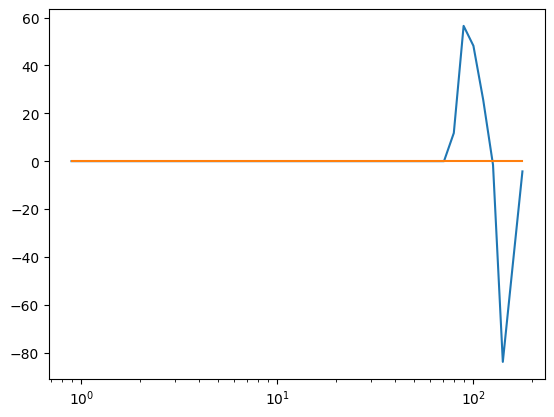

In [19]:
fig,ax = plt.subplots()
# plt.plot(r, s, '.-')
# plt.plot(r, hr.real, '.-')
# plt.plot(r, hr.imag, '.-')
plt.plot(r, (s).real)
plt.plot(r, (s).imag)
plt.xscale('log')

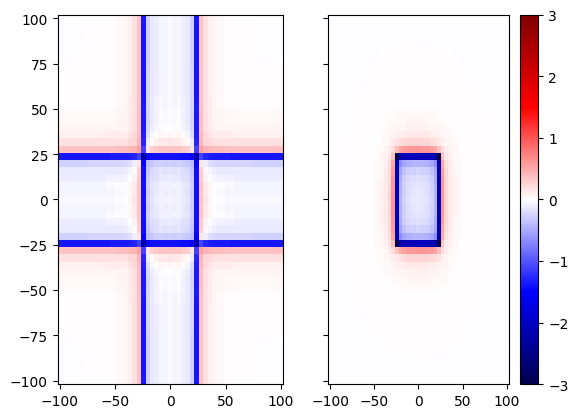

In [20]:
fig,axs = plt.subplots(1,2, sharex=True, sharey=True)
pcm = axs[0].pcolor(xy, xy, HZ.real, vmin=-3, vmax=3, cmap='seismic')
pcm = axs[1].pcolor(xy, xy, HZ2.real, vmin=-3, vmax=3, cmap='seismic')
plt.colorbar(pcm)

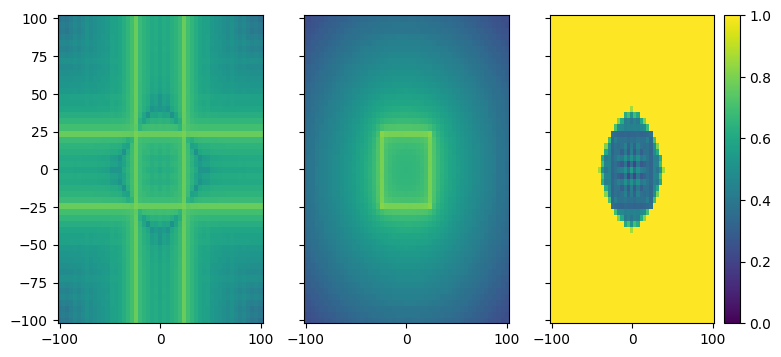

: 

In [21]:
fig,axs = plt.subplots(1,3, sharex=True, sharey=True, figsize=(9,4))
pcm = axs[0].pcolor(xy, xy, np.log10(np.abs(HZ)), vmin=-6, vmax=2)
pcm = axs[1].pcolor(xy, xy, np.log10(np.abs(HZ2)), vmin=-6, vmax=2)
pcm=axs[2].pcolor(xy, xy, np.abs((HZ2-HZ)/HZ2), vmin=0, vmax=1)
plt.colorbar(pcm)

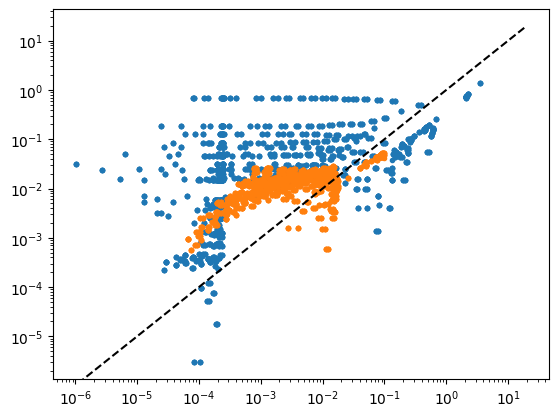

In [22]:
plt.figure()
plt.plot(np.abs(HZ2.flatten().real), np.abs(HZ.flatten().real), '.')
plt.plot(np.abs(HZ2.flatten().imag), np.abs(HZ.flatten().imag), '.')
plt.plot([0,20], [0, 20], 'k--')
plt.yscale('log')
plt.xscale('log')

In [41]:
import torch._dynamo
torch._dynamo.config.suppress_errors = True

import torch
import torchvision.models as models

model = models.resnet18()#.cuda()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
compiled_model = torch.compile(model)

x = torch.randn(16, 3, 224, 224)#.cuda()
#optimizer.zero_grad()
out = compiled_model(x)
out.sum().backward()
optimizer.step()

[2024-01-10 15:04:09,717] torch._dynamo.convert_frame: [WARNING] WON'T CONVERT forward /home/matt/repositories/em1d/.venv/lib/python3.10/site-packages/torchvision/models/resnet.py line 284 
[2024-01-10 15:04:09,717] torch._dynamo.convert_frame: [WARNING] due to: 
[2024-01-10 15:04:09,717] torch._dynamo.convert_frame: [WARNING] Traceback (most recent call last):
[2024-01-10 15:04:09,717] torch._dynamo.convert_frame: [WARNING]   File "/home/matt/repositories/em1d/.venv/lib/python3.10/site-packages/torch/utils/cpp_extension.py", line 9, in <module>
[2024-01-10 15:04:09,717] torch._dynamo.convert_frame: [WARNING]     import setuptools
[2024-01-10 15:04:09,717] torch._dynamo.convert_frame: [WARNING] torch._dynamo.exc.BackendCompilerFailed: backend='inductor' raised:
[2024-01-10 15:04:09,717] torch._dynamo.convert_frame: [WARNING] ModuleNotFoundError: No module named 'setuptools'
[2024-01-10 15:04:09,717] torch._dynamo.convert_frame: [WARNING] 
[2024-01-10 15:04:09,717] torch._dynamo.convert

In [44]:
# out.sum().backward()
optimizer.step()